# Customer Churn Prediction on Online Retail II

**Name:** Bharat Parashar  
**Roll Number:** 24035010616  
**Course:** DA 377 - Term Project-1

**Problem.** Retailers depend on repeat customers to maintain sales. However, some customers gradually stop purchasing, and the business may not realise it.

**Task.** Develop a machine-learning model using historical purchase data to predict whether consumers are likely to stop purchasing during the defined future period.

**Data.** Online Retail II from the UCI Machine Learning Repository: transactions from a UK-based giftware retailer, covering 1 December 2009 to 9 December 2011. I define one using a time split.

**Workflow:** `load -> clean -> explore -> define churn -> build customer features -> split -> compare and tune models -> choose threshold -> evaluate -> interpret results for business use`

**1. Setup: Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    cross_val_predict, RandomizedSearchCV
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay, classification_report
)
import sys, platform, psutil
print("OS     :", platform.system(), platform.release())
print("CPU    :", platform.processor())
print("RAM    :", round(psutil.virtual_memory().total / (1024**3)), "GB")
print("Python :", sys.version.split()[0])
print("pandas :", pd.__version__)
print("numpy  :", np.__version__)
print("sklearn:", sklearn.__version__)

OS     : Windows 11
CPU    : AMD64 Family 23 Model 104 Stepping 1, AuthenticAMD
RAM    : 15 GB
Python : 3.13.14
pandas : 3.0.3
numpy  : 2.4.6
sklearn: 1.9.0


**2. Loading Dataset**

In [2]:
sheet1 = pd.read_excel('online_retail.xlsx', sheet_name='Year 2009-2010')
sheet2 = pd.read_excel('online_retail.xlsx', sheet_name='Year 2010-2011')

# Combine both years into one table with a fresh, continuous index.
df_raw = pd.concat([sheet1, sheet2], ignore_index=True)
print("Shape:", df_raw.shape)

Shape: (1067371, 8)


**3. Understanding Dataset**

In [3]:
df_raw.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 78.8+ MB



| Column Name | Data Type | Description | Business Meaning |
|---|---|---|---|
| `Invoice` | Object / String | 6-digit invoice number | Unique purchase identifier. Starts with **'C'** if the order was cancelled/returned. |
| `StockCode` | Object / String | Product item code | Unique identifier for each merchandise item. |
| `Description` | Object / String | Product name | Text description of the product. |
| `Quantity` | Integer | Units per line item | Number of units purchased. Negative values indicate cancellations/adjustments. |
| `InvoiceDate` | Datetime | Date and time | Timestamp when the transaction took place. |
| `Price` | Float | Unit price (£ GBP) | Price of a single unit in British Pounds Sterling. |
| `Customer ID` | Float / Integer | Customer identifier | Unique identifier for each registered customer. Missing for unregistered guest checkouts. |
| `Country` | Object / String | Customer location | Country where the customer resides. |

Each row is one **line item** of an invoice. One customer can have many invoices and one invoice can have many lines.

In [5]:
df_raw.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394029,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [49]:
# data analysis
print("Missing Values:\n", df_raw.isnull().sum())

print("Duplicate Rows:", df_raw.duplicated().sum())

is_cancel = df_raw['Invoice'].astype(str).str.startswith('C')
print("Cancellation Rows:", is_cancel.sum())

print("Non-positive Quantity:", (df_raw['Quantity'] <= 0).sum())
print("Non-positive Price:", (df_raw['Price'] <= 0).sum())

Missing Values:
 Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64
Duplicate Rows: 34335
Cancellation Rows: 19494
Non-positive Quantity: 22950
Non-positive Price: 6207


**4. Data Cleaning**




| Step | Reason |
|---|---|
| Drop missing Customer ID | Churn is a customer-level outcome; guests cannot be tracked. |
| Drop exact duplicate rows | Same invoice, product, quantity, price and time repeated; treated as data-entry duplicates. |
| Separate cancellations (Invoice starts with `C`) | Not purchases. I **keep them in `df_cancel`** because the number of cancellations before the cutoff may be a useful feature. |
| Keep only real product codes (start with 5 digits) | Removes non-product codes like `POST`, `DOT`, `M`, bank charges, etc. |
| Drop Quantity ≤ 0 or Price ≤ 0 | Not valid sales lines. |
| Remove purchases that were fully cancelled (step 4.7) | An order that was placed and then cancelled with the same quantity is not a real sale. Keeping it would add fake revenue and fake purchases. |

In [50]:
#Remove rows with missing Customer ID
df = df_raw.dropna(subset=['Customer ID']).copy()
df['Customer ID'] = df['Customer ID'].astype(int)
print("After step 4.1 (remove missing Customer ID):", len(df))

#Remove exact duplicate rows
df = df.drop_duplicates()
print("After step 4.2 (remove exact duplicates):", len(df))

#Separate cancellation invoices and keep them for future use
df['Invoice'] = df['Invoice'].astype(str)
is_cancel = df['Invoice'].str.startswith('C')

df_cancel = df[is_cancel].copy()
df = df[~is_cancel].copy()
print("Cancellation rows stored in df_cancel after step 4.3:", len(df_cancel))
print("Purchase rows remaining after step 4.3:", len(df))

#Keep valid product codes (codes beginning with five digits)
df = df[df['StockCode'].astype(str).str.match(r'^\d{5}')].copy()
print("After step 4.4 (keep valid product codes):", len(df))

#Remove non-positive quantities and prices
df = df[(df['Quantity'] > 0) & (df['Price'] > 0)].copy()
print("After step 4.5 (positive quantity and price only):", len(df))

After step 4.1 (remove missing Customer ID): 824364
After step 4.2 (remove exact duplicates): 797885
Cancellation rows stored in df_cancel after step 4.3: 18390
Purchase rows remaining after step 4.3: 779495
After step 4.4 (keep valid product codes): 776637
After step 4.5 (positive quantity and price only): 776577


In [51]:
#Create TotalPrice = Quantity x Price
df['TotalPrice'] = df['Quantity'] * df['Price']
print("After step 4.6 (create TotalPrice):", len(df))

After step 4.6 (create TotalPrice): 776577


In [ ]:
#purchases: remember the original row number so we know which row to drop
purch = df[["Customer ID", "StockCode", "Quantity", "InvoiceDate"]].copy()
purch["purch_index"] = purch.index
purch = purch.sort_values("InvoiceDate")

#cancellations: make the quantity positive so it can match the purchase quantity
canc = df_cancel[["Customer ID", "StockCode", "Quantity", "InvoiceDate"]].copy()
canc["Quantity"] = canc["Quantity"].abs()
canc = canc.sort_values("InvoiceDate")

#for every cancellation, find the latest earlier purchase with the same customer, product and quantity
matched = pd.merge_asof(canc, purch, on="InvoiceDate", by=["Customer ID", "StockCode", "Quantity"], direction="backward")
cancelled_rows = matched["purch_index"].dropna().astype(int).unique()

removed = df.loc[cancelled_rows]
print("Purchase lines removed:", len(removed))
print("Fake revenue removed (£):", round(removed["TotalPrice"].sum(), 2))
print("\nLargest removed lines:")
display(removed.nlargest(5, "TotalPrice")[["Invoice", "Description", "Quantity", "Price", "TotalPrice", "Customer ID"]])

df = df.drop(cancelled_rows)
print("After step 4.7 (remove fully cancelled purchases):", len(df))

Purchase lines removed: 6179
Fake revenue removed (£): 601508.37

Largest removed lines:


,Invoice,Description,Quantity,Price,TotalPrice,Customer ID
1065882,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446
587080,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,12346
748132,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.0,15098
432176,530715,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,15818.4,15838
578172,540815,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.4,15749


After step 4.7 (remove fully cancelled purchases): 770398


In [10]:
df[['Quantity', 'Price', 'TotalPrice']].describe()

,Quantity,Price,TotalPrice
count,770398.000000,770398.000000,770398.000000
mean,13.107529,2.913169,21.374743
std,72.415702,4.033437,65.644203
min,1.000000,0.030000,0.060000
25%,2.000000,1.250000,4.950000
50%,6.000000,1.950000,11.900000
75%,12.000000,3.750000,19.500000
max,19152.000000,649.500000,8925.000000


**5. Exploratory Data Analysis**

In [ ]:
#Date range
print("Date Range:")
print(df['InvoiceDate'].min(), "to", df['InvoiceDate'].max())
# 2. Total invoices
print("Total Invoices:", df['Invoice'].nunique())
# 3. Total customers
print("Total Customers:", df['Customer ID'].nunique())
# 4. Total products
print("Total Products:", df['StockCode'].nunique())
# 5. Total countries
print("Total Countries:", df['Country'].nunique())
# 6. Total revenue
print("Total Revenue (£):", round(df['TotalPrice'].sum(), 2))
# 7. Total transaction records
print("Total Rows:", len(df))

Date Range:
2009-12-01 07:45:00 to 2011-12-09 12:50:00
Total Invoices: 36329
Total Customers: 5839
Total Products: 4611
Total Countries: 41
Total Revenue (£): 16467059.6
Total Rows: 770398


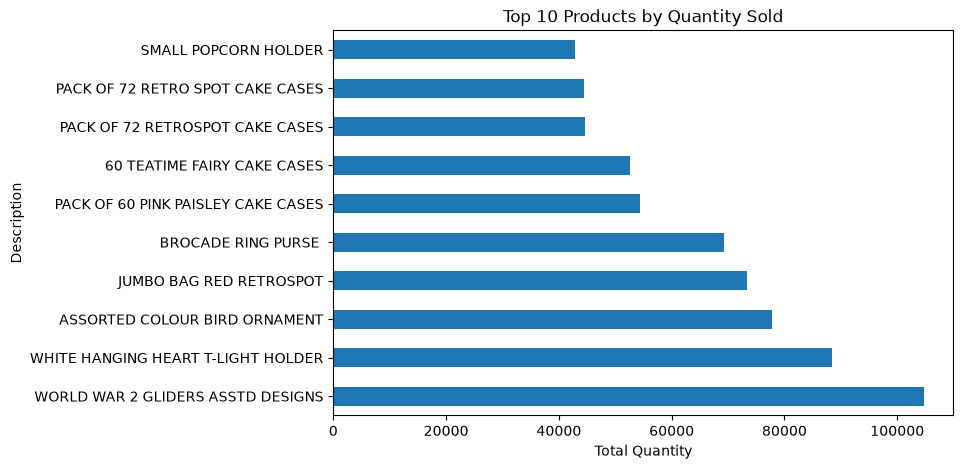

In [12]:
top_products = df.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)
top_products.plot(kind="barh", figsize=(8, 5), title="Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity")
plt.show()

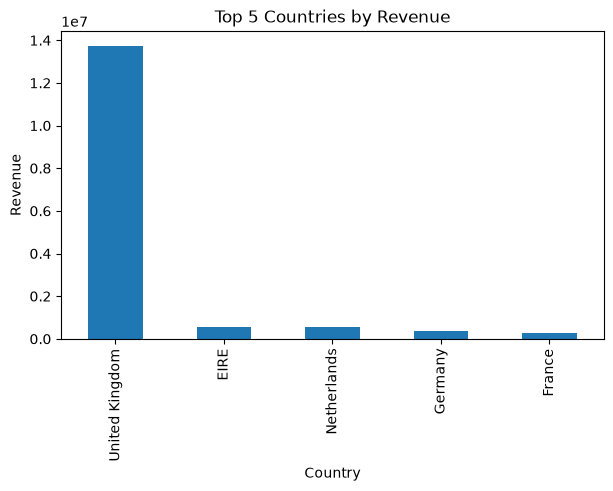

In [13]:
top_countries = df.groupby("Country")["TotalPrice"].sum().sort_values(ascending=False).head(5)
top_countries.plot(kind="bar", figsize=(7, 4), title="Top 5 Countries by Revenue")
plt.ylabel("Revenue")
plt.show()

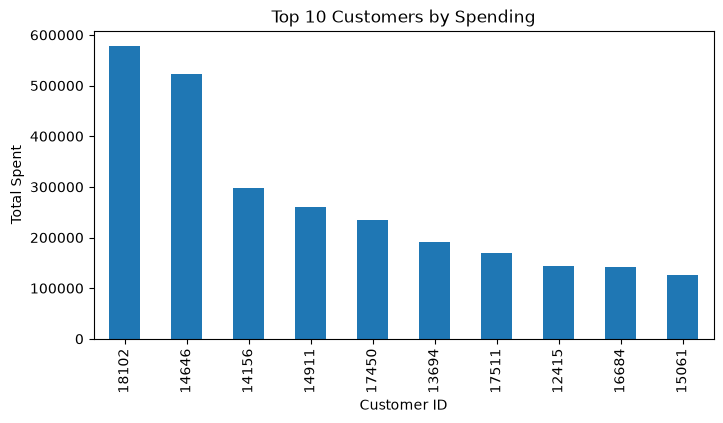

In [14]:
top_customers = df.groupby("Customer ID")["TotalPrice"].sum().sort_values(ascending=False).head(10)
top_customers.plot(kind="bar", figsize=(8, 4), title="Top 10 Customers by Spending")
plt.ylabel("Total Spent")
plt.show()

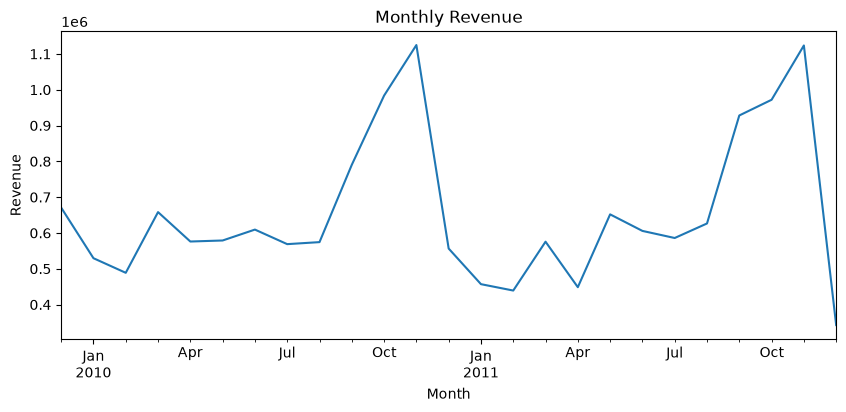

In [15]:
df["Month"] = df["InvoiceDate"].dt.to_period("M")
monthly = df.groupby("Month")["TotalPrice"].sum()
monthly.plot(figsize=(10, 4), title="Monthly Revenue")
plt.ylabel("Revenue")
plt.show()

In [ ]:
# highest and lowest revenue months
highest_month = monthly.idxmax()
lowest_month = monthly.idxmin()

print("Highest Revenue Month:")
print(highest_month, monthly.max())

print("Lowest Revenue Month:")
print(lowest_month, monthly.min())

#Checking last month in the dataset
last_month = monthly.index[-1]

print("Last Month:", last_month)
print("Dataset ends on:", df['InvoiceDate'].max())

Highest Revenue Month:
2010-11 1124729.19
Lowest Revenue Month:
2011-12 342870.76
Last Month: 2011-12
Dataset ends on: 2011-12-09 12:50:00


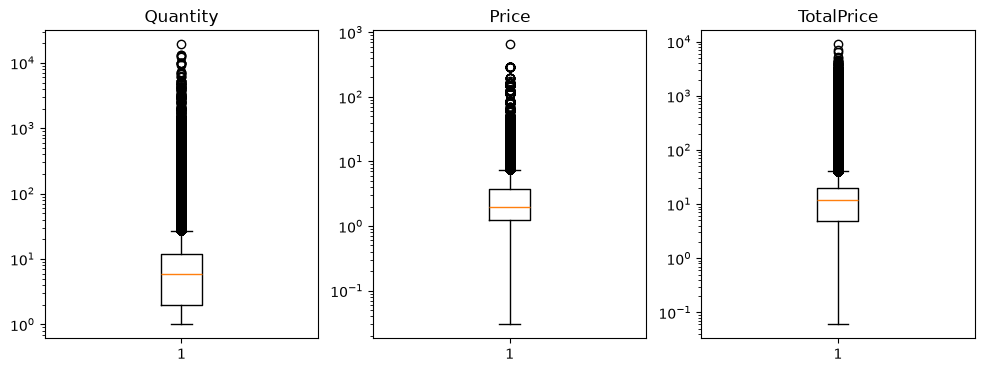

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ["Quantity", "Price", "TotalPrice"]):
    ax.boxplot(df[col])
    ax.set_yscale("log")
    ax.set_title(col)
plt.show()

In [18]:
Q1 = df["TotalPrice"].quantile(0.25)
Q3 = df["TotalPrice"].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
print("Upper limit:", upper)
print("Outlier rows:", (df["TotalPrice"] > upper).sum())

Upper limit: 41.325
Outlier rows: 62750


**IQR outlier decision: kept.** High transaction values can be bulk purchases.

In [19]:
df.nlargest(5, "TotalPrice")[["Invoice", "Description", "Quantity", "Price", "TotalPrice", "Customer ID"]]

,Invoice,Description,Quantity,Price,TotalPrice,Customer ID
228042,511465,PINK PAPER PARASOL,3500,2.55,8925.00,18008
873786,567423,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,17450
686007,550461,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749
379875,525968,ROTATING SILVER ANGELS T-LIGHT HLDR,3120,1.66,5179.20,15838
947062,573003,RABBIT NIGHT LIGHT,2400,2.08,4992.00,14646


**6. Defining Customer Churn**

Cutoff date: 1 July 2011. Only customers with a purchase before this date are included, and their features use pre-cutoff transactions only.  
Label window: 1 July 2011 through 9 December 2011, a 162-day evaluation window.  
Churn definition: A customer is labelled `Churn = 1` if they make no purchase in this window; otherwise, `Churn = 0`.

In [52]:
#Split transactions at the cutoff date.
cutoff = pd.Timestamp("2011-07-01")
before = df[df["InvoiceDate"] < cutoff]    #Features: past purchases only
after = df[df["InvoiceDate"] >= cutoff]   #Labels: future purchases only

assert before["InvoiceDate"].max() < cutoff
assert after["InvoiceDate"].min() >= cutoff

print("Before:", before.shape)
print("After:", after.shape)

Before: (555397, 9)
After: (221180, 9)


In [56]:
#one row per customer who bought BEFORE the cutoff
customers = pd.DataFrame({"Customer ID": before["Customer ID"].unique()})

#customers who bought AFTER the cutoff
returned = after["Customer ID"].unique()

#churn = 1 if the customer did NOT come back, else 0
customers["Churn"] = (~customers["Customer ID"].isin(returned)).astype(int)
customers.head()

,Customer ID,Churn
0,13085,0
1,13078,0
2,15362,1
3,18102,0
4,12682,0


Churn
0    2519
1    2489
Name: count, dtype: int64
Churn
0    50.299521
1    49.700479
Name: proportion, dtype: float64


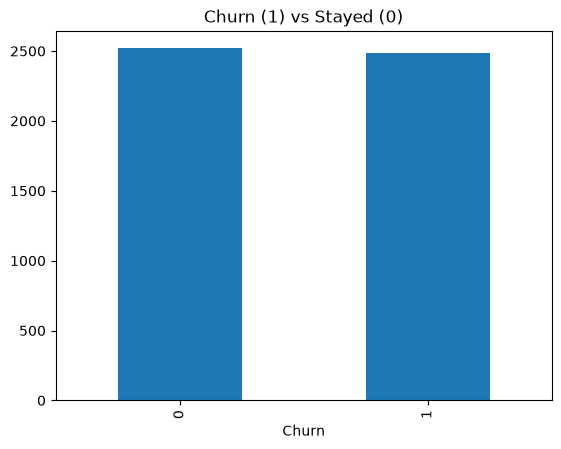

In [22]:
print(customers["Churn"].value_counts())
print(customers["Churn"].value_counts(normalize=True) * 100)
customers["Churn"].value_counts().plot(kind="bar", title="Churn (1) vs Stayed (0)")
plt.show()

In [57]:
#days between a customer's purchase days (before the cutoff only)
order_days = (before.assign(Day=before["InvoiceDate"].dt.normalize())
                    [["Customer ID", "Day"]].drop_duplicates()
                    .sort_values(["Customer ID", "Day"]))
gaps = order_days.groupby("Customer ID")["Day"].diff().dt.days.dropna()

print(gaps.describe().round(1))
share_long = (gaps > 162).mean() * 100
print("Share of gaps longer than 162 days:", round(share_long, 1), "%")
if share_long < 10:
    print("Finding: long silences are rare, so 162 days without a purchase is a reasonable sign of leaving.")
else:
    print("Finding: long silences are common, so some 'churned' customers may just be slow, occasional buyers.")

count    19130.0
mean        52.7
std         63.0
min          1.0
25%         13.0
50%         31.0
75%         66.0
max        540.0
Name: Day, dtype: float64
Share of gaps longer than 162 days: 6.6 %
Finding: long silences are rare, so 162 days without a purchase is a reasonable sign of leaving.


In [24]:
days_per_customer = order_days.groupby("Customer ID").size().rename("PurchaseDays").reset_index()
check = customers.merge(days_per_customer, on="Customer ID")
check["OneDayBuyer"] = (check["PurchaseDays"] == 1)

print("Share of customers who bought on only one day:", round(check["OneDayBuyer"].mean() * 100, 1), "%")
print("\nChurn rate (%) by group:")
print((check.groupby("OneDayBuyer")["Churn"].mean() * 100).round(1))

Share of customers who bought on only one day: 32.3 %

Churn rate (%) by group:
OneDayBuyer
False    37.8
True     74.7
Name: Churn, dtype: float64


**7. Feature Engineering (one row per customer)**

In [61]:
#RFM + tenure + average order value, from BEFORE-cutoff purchases only
features = before.groupby("Customer ID").agg(
    FirstPurchase=("InvoiceDate", "min"),
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("TotalPrice", "sum"),
).reset_index()

features["Recency"] = (cutoff - features["LastPurchase"]).dt.days
features["Tenure"] = (cutoff - features["FirstPurchase"]).dt.days
features["AvgOrderValue"] = features["Monetary"] / features["Frequency"]
features.head()

,Customer ID,FirstPurchase,LastPurchase,Frequency,Monetary,Recency,Tenure,AvgOrderValue
0,12346,2010-03-02 13:08:00,2011-01-18 10:01:00,3,77352.96,163,485,25784.320
1,12347,2010-10-31 14:20:00,2011-06-09 13:01:00,5,2817.48,21,242,563.496
2,12348,2010-09-27 14:59:00,2011-04-05 10:47:00,4,1388.40,86,276,347.100
3,12349,2010-04-29 13:20:00,2010-10-28 08:23:00,2,2221.14,245,427,1110.570
4,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,294.40,148,148,294.400


In [62]:
#Cancellations before the cutoff (customers with none get 0)
cancel_before = df_cancel[df_cancel["InvoiceDate"] < cutoff]
cancel_counts = (cancel_before.groupby("Customer ID")["Invoice"].nunique()
                 .rename("Cancellations").reset_index())

features = features.merge(cancel_counts, on="Customer ID", how="left")
features["Cancellations"] = features["Cancellations"].fillna(0).astype(int)

In [63]:
#Attach the churn label to the customer-level features.
use_cols = ["Recency", "Frequency", "Monetary", "AvgOrderValue", "Tenure", "Cancellations"]

data = features.merge(customers, on="Customer ID")
data = data[["Customer ID"] + use_cols + ["Churn"]]

assert len(data) == len(customers)
assert data["Customer ID"].is_unique
print(data.shape)
data.head()

(5016, 8)


,Customer ID,Recency,Frequency,Monetary,AvgOrderValue,Tenure,Cancellations,Churn
0,12346,163,3,77352.96,25784.320,485,5,1
1,12347,21,5,2817.48,563.496,242,0,0
2,12348,86,4,1388.40,347.100,276,0,0
3,12349,245,2,2221.14,1110.570,427,1,0
4,12350,148,1,294.40,294.400,148,0,1


In [64]:
#Do churned customers look different? (average of each feature per group)
data.groupby("Churn")[use_cols].mean().round(1)

,Recency,Frequency,Monetary,AvgOrderValue,Tenure,Cancellations
Churn,,,,,,
0,109.1,8.0,3887.3,398.0,392.7,1.8
1,247.3,2.7,979.2,347.6,364.4,0.6


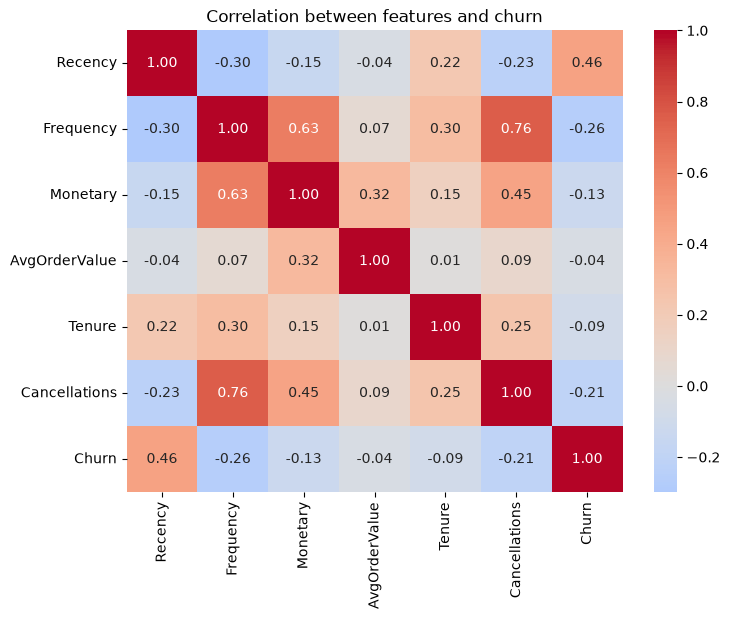

In [66]:
#Correlation heatmap (features and churn)
plt.figure(figsize=(8, 6))
sns.heatmap(data[use_cols + ["Churn"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between features and churn")
plt.show()

In [67]:
#Findings, written from the numbers above
g = data.groupby("Churn")[["Recency", "Frequency", "Monetary"]].median()
print("Median Recency   : churned", g.loc[1, "Recency"], "days vs stayed", g.loc[0, "Recency"], "days")
print("Median Frequency : churned", g.loc[1, "Frequency"], "orders vs stayed", g.loc[0, "Frequency"], "orders")
print("Median Monetary  : churned", round(g.loc[1, "Monetary"]), "vs stayed", round(g.loc[0, "Monetary"]))
corr_with_churn = data[use_cols + ["Churn"]].corr()["Churn"].drop("Churn")
print("\nStrongest link with churn:", corr_with_churn.abs().idxmax(), "(correlation", round(corr_with_churn[corr_with_churn.abs().idxmax()], 2), ")")
print("Correlation of Cancellations with Frequency:", round(data["Cancellations"].corr(data["Frequency"]), 2))

Median Recency   : churned 237.0 days vs stayed 56.5 days
Median Frequency : churned 2.0 orders vs stayed 5.0 orders
Median Monetary  : churned 413 vs stayed 1464

Strongest link with churn: Recency (correlation 0.46 )
Correlation of Cancellations with Frequency: 0.76


**8. Train / Test Split**

In [36]:
X_all = data[use_cols]
y = data["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate train:", round(y_train.mean() * 100, 1), "%  | test:", round(y_test.mean() * 100, 1), "%")

Train: (4006, 6)  Test: (1002, 6)
Churn rate train: 49.7 %  | test: 49.7 %


**9. Models and Cross-Validation (training set only)**

In [68]:
#Create 5-fold stratified cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Create Logistic Regression pipeline
lr_pipe = make_pipeline(
    FunctionTransformer(np.log1p),
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=42
)

# Evaluate both models using cross-validation
lr_scores = cross_val_score(
    lr_pipe, X_train, y_train, cv=cv, scoring="roc_auc"
)

rf_scores = cross_val_score(
    rf_model, X_train, y_train, cv=cv, scoring="roc_auc"
)

# Create comparison table
cv_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "CV ROC-AUC (mean)": [lr_scores.mean(), rf_scores.mean()],
    "Std": [lr_scores.std(), rf_scores.std()]
}).round(3)

cv_results

,Model,CV ROC-AUC (mean),Std
0,Logistic Regression,0.802,0.010
1,Random Forest,0.796,0.009


In [69]:
#Summarise the cross-validation comparison.
best_row = cv_results.loc[cv_results["CV ROC-AUC (mean)"].idxmax()]
spread = cv_results["CV ROC-AUC (mean)"].max() - cv_results["CV ROC-AUC (mean)"].min()
print("Best model in cross-validation:", best_row["Model"], "(ROC-AUC", best_row["CV ROC-AUC (mean)"], ")")
print("Gap between the two models:", round(spread, 3))

Best model in cross-validation: Logistic Regression (ROC-AUC 0.802 )
Gap between the two models: 0.006


In [39]:
rf_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 8, None],
    "min_samples_leaf": [1, 5, 10, 20],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42), rf_params, n_iter=15,
    cv=cv, scoring="roc_auc", random_state=42, n_jobs=-1
)
rf_search.fit(X_train, y_train)

print("Random Forest (tuned) CV ROC-AUC:", round(rf_search.best_score_, 3))
print("Best parameters:", rf_search.best_params_)

Random Forest (tuned) CV ROC-AUC: 0.807
Best parameters: {'n_estimators': 200, 'min_samples_leaf': 10, 'max_depth': 5}


**10. Final Model Selection**

I select the tuned Random Forest only if its mean 5-fold cross-validated ROC-AUC is at least **0.005 higher** than Logistic Regression; otherwise, I keep Logistic Regression. This pre-set margin avoids switching models for a gain smaller than the minimum improvement I consider meaningful.

In [40]:
lr_pipe.fit(X_train, y_train)

# Keep Random Forest only if it clearly improves on Logistic Regression.
if rf_search.best_score_ >= lr_scores.mean() + 0.005:
    final_name, final_model = "Random Forest (tuned)", rf_search.best_estimator_
else:
    final_name, final_model = "Logistic Regression", lr_pipe

print("Random Forest (tuned) CV ROC-AUC:", round(rf_search.best_score_, 3))
print("Logistic Regression CV ROC-AUC:", round(lr_scores.mean(), 3))
print("Final model:", final_name)

Random Forest (tuned) CV ROC-AUC: 0.807
Logistic Regression CV ROC-AUC: 0.802
Final model: Random Forest (tuned)


**11. Choosing the Decision Threshold (training data only)**

The model outputs a **probability of churn**. The default rule is: probability ? 0.5 means churn (1). A **lower** threshold catches more churners (higher **recall**) but flags more customers who would have stayed (lower **precision**).

I target **90% recall** because the business goal is to catch as many potentially lost customers as possible for retention outreach; this deliberately favours recall over precision. I choose the highest threshold that reaches this target using out-of-fold predictions on the training data only. If no threshold reaches 90%, the code falls back to the threshold with the best F1 score.

In [41]:
train_prob = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

rows = []
for t in np.arange(0.20, 0.81, 0.05):
    pred = (train_prob >= t).astype(int)
    rows.append([round(t, 2), precision_score(y_train, pred, zero_division=0), recall_score(y_train, pred),
                 f1_score(y_train, pred), pred.mean() * 100])

threshold_table = pd.DataFrame(rows, columns=["Threshold", "Precision", "Recall", "F1", "Flagged %"]).round(3)
display(threshold_table)

# threshold with the best F1
thr_f1 = float(threshold_table.loc[threshold_table["F1"].idxmax(), "Threshold"])

# recall target: the highest threshold that still catches at least 90% of churners
target_recall = 0.90
reached = threshold_table[threshold_table["Recall"] >= target_recall]
if len(reached) > 0:
    threshold = float(reached["Threshold"].max())
else:
    threshold = thr_f1

print("Best-F1 threshold:", thr_f1, "| Chosen threshold (recall target", target_recall, "):", threshold)

,Threshold,Precision,Recall,F1,Flagged %
0,0.20,0.592,0.970,0.736,81.428
1,0.25,0.605,0.959,0.742,78.832
2,0.30,0.620,0.940,0.747,75.287
3,0.35,0.643,0.909,0.753,70.245
4,0.40,0.667,0.867,0.754,64.628
5,0.45,0.689,0.834,0.755,60.160
6,0.50,0.704,0.785,0.743,55.392
7,0.55,0.720,0.724,0.722,50.025
8,0.60,0.751,0.634,0.688,41.987
9,0.65,0.777,0.532,0.631,34.024


Best-F1 threshold: 0.45 | Chosen threshold (recall target 0.9 ): 0.35


**12. Held-out Test Evaluation**

In [42]:
# Compare the baseline and both predictive models on the test set.
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_prob = dummy.predict_proba(X_test)[:, 1]

lr_prob = lr_pipe.predict_proba(X_test)[:, 1]
rf_prob = rf_search.best_estimator_.predict_proba(X_test)[:, 1]
test_prob = final_model.predict_proba(X_test)[:, 1]

runs = [
    ("Dummy Classifier", dummy_prob, 0.5),
    ("Logistic Regression", lr_prob, 0.5),
    ("Random Forest (tuned)", rf_prob, 0.5),
    (final_name + " @ best-F1 threshold", test_prob, thr_f1),
    (final_name + " @ chosen threshold", test_prob, threshold),
]

rows = []
for name, prob, thr in runs:
    pred = (prob >= thr).astype(int)
    rows.append([name, thr, accuracy_score(y_test, pred), precision_score(y_test, pred, zero_division=0),
                 recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, prob)])

test_results = pd.DataFrame(rows, columns=["Model", "Threshold", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]).round(3)
test_results

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
0,Dummy Classifier,0.50,0.503,0.000,0.000,0.000,0.500
1,Logistic Regression,0.50,0.730,0.722,0.741,0.731,0.800
2,Random Forest (tuned),0.50,0.736,0.717,0.773,0.744,0.814
3,Random Forest (tuned) @ best-F1 threshold,0.45,0.728,0.696,0.803,0.746,0.814
4,Random Forest (tuned) @ chosen threshold,0.35,0.708,0.648,0.900,0.754,0.814


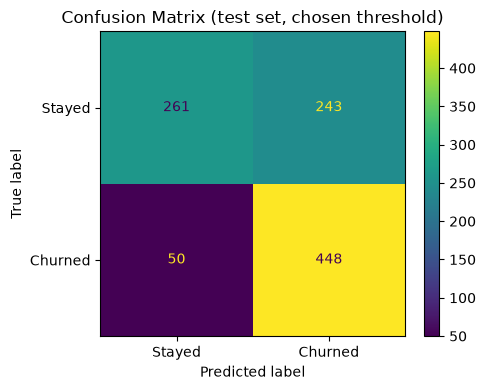

              precision    recall  f1-score   support

      Stayed       0.84      0.52      0.64       504
     Churned       0.65      0.90      0.75       498

    accuracy                           0.71      1002
   macro avg       0.74      0.71      0.70      1002
weighted avg       0.74      0.71      0.70      1002



In [43]:
# Apply the selected threshold to the selected model's test probabilities.
test_pred = (test_prob >= threshold).astype(int)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["Stayed", "Churned"], ax=ax
)
ax.set_title("Confusion Matrix (test set, chosen threshold)")
plt.tight_layout()
plt.show()

print(classification_report(y_test, test_pred, target_names=["Stayed", "Churned"]))

In [44]:
rng = np.random.default_rng(42)
y_arr = y_test.values
auc_rf, auc_lr, auc_diff = [], [], []

for _ in range(500):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    auc_rf.append(roc_auc_score(y_arr[idx], rf_prob[idx]))
    auc_lr.append(roc_auc_score(y_arr[idx], lr_prob[idx]))
    auc_diff.append(auc_rf[-1] - auc_lr[-1])

print("Random Forest ROC-AUC 95% range:", np.percentile(auc_rf, [2.5, 97.5]).round(3))
print("Logistic Regression ROC-AUC 95% range:", np.percentile(auc_lr, [2.5, 97.5]).round(3))
low, high = np.percentile(auc_diff, [2.5, 97.5])
print("Difference (Random Forest minus Logistic Regression) 95% range:", round(low, 3), "to", round(high, 3))
if low <= 0 <= high:
    print("Finding: the interval includes 0, so this test set does not show a clear difference.")
else:
    print("Finding: the interval does not include 0, suggesting a difference on this test split.")

Random Forest ROC-AUC 95% range: [0.788 0.838]
Logistic Regression ROC-AUC 95% range: [0.771 0.826]
Difference (Random Forest minus Logistic Regression) 95% range: 0.006 to 0.022
Finding: the interval does not include 0, suggesting a difference on this test split.


In [45]:
test_df = pd.DataFrame({
    "Customer ID": data.loc[X_test.index, "Customer ID"].values,
    "Churn": y_test.values,
    "Prob": test_prob,
})
test_df = test_df.sort_values("Prob", ascending=False).reset_index(drop=True)
test_df["Decile"] = pd.qcut(test_df["Prob"].rank(method="first", ascending=False), 10, labels=range(1, 11))

decile = test_df.groupby("Decile", observed=True).agg(Customers=("Churn", "size"), Churners=("Churn", "sum"))
decile["Churn rate %"] = (decile["Churners"] / decile["Customers"] * 100).round(1)
decile["Cumulative churners caught %"] = (decile["Churners"].cumsum() / decile["Churners"].sum() * 100).round(1)
decile["Lift"] = (decile["Churn rate %"] / (y_test.mean() * 100)).round(2)
decile

,Customers,Churners,Churn rate %,Cumulative churners caught %,Lift
Decile,,,,,
1,101,92,91.1,18.5,1.83
2,100,80,80.0,34.5,1.61
3,100,66,66.0,47.8,1.33
4,100,67,67.0,61.2,1.35
5,100,62,62.0,73.7,1.25
6,100,46,46.0,82.9,0.93
7,100,40,40.0,91.0,0.80
8,100,27,27.0,96.4,0.54
9,100,13,13.0,99.0,0.26


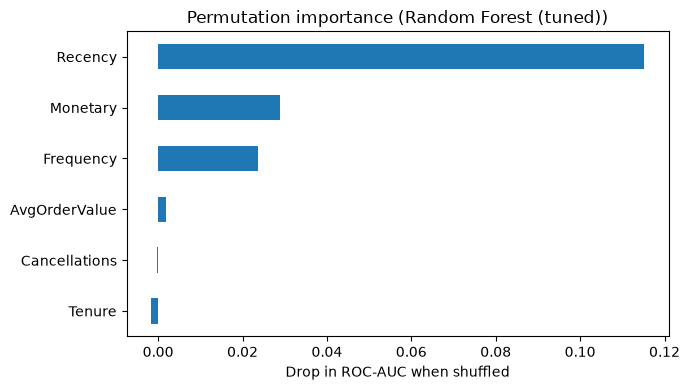

Most important feature (permutation): Recency


Recency          0.115
Monetary         0.029
Frequency        0.024
AvgOrderValue    0.002
Cancellations   -0.000
Tenure          -0.002
dtype: float64

In [46]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42)
perm_imp = pd.Series(perm.importances_mean, index=use_cols).sort_values()

plt.figure(figsize=(7, 4))
perm_imp.plot(kind="barh", title="Permutation importance (" + final_name + ")")
plt.xlabel("Drop in ROC-AUC when shuffled")
plt.tight_layout()
plt.show()

print("Most important feature (permutation):", perm_imp.idxmax())
perm_imp.sort_values(ascending=False).round(3)

In [47]:
missed = (y_test.values == 1) & (test_pred == 0)
caught = (y_test.values == 1) & (test_pred == 1)
stayed = (y_test.values == 0)

print("Churners caught:", caught.sum(), "| churners missed:", missed.sum(), "| stayers:", stayed.sum())
pd.DataFrame({
    "Churners caught": X_test[caught].mean(),
    "Churners missed": X_test[missed].mean(),
    "Stayers": X_test[stayed].mean(),
}).round(1)

Churners caught: 448 | churners missed: 50 | stayers: 504


,Churners caught,Churners missed,Stayers
Recency,272.3,62.3,108.2
Frequency,2.1,6.6,7.8
Monetary,633.1,3707.1,4102.2
AvgOrderValue,281.7,884.8,384.4
Tenure,362.8,371.5,394.8
Cancellations,0.4,2.3,1.7


In [48]:
final_row = test_results.loc[test_results["Model"].str.endswith("@ chosen threshold")].iloc[0]
majority_row = test_results.loc[test_results["Model"] == "Dummy Classifier"].iloc[0]
best_f1_row = test_results.loc[test_results["Model"].str.endswith("@ best-F1 threshold")].iloc[0]

print("Customers modelled        :", len(data), "(churn rate", round(data["Churn"].mean() * 100, 1), "%)")
print("Features used             :", len(use_cols), use_cols)
print("Cross-validated ROC-AUC   : LR", round(lr_scores.mean(), 3), "| RF", round(rf_scores.mean(), 3), "| Tuned RF", round(rf_search.best_score_, 3))
print("Final model               :", final_name)
print("Test ROC-AUC              :", final_row["ROC-AUC"], "(Dummy baseline", majority_row["ROC-AUC"], ")")
print("Test accuracy             :", final_row["Accuracy"], "(Dummy baseline", majority_row["Accuracy"], ")")
print("Chosen threshold          :", threshold, "-> recall", final_row["Recall"], ", precision", final_row["Precision"])
print("Best-F1 threshold         :", thr_f1, "-> recall", best_f1_row["Recall"], ", precision", best_f1_row["Precision"])
print("Top feature               :", perm_imp.idxmax())
print("Top 20% of risk catches   :", decile.loc[2, "Cumulative churners caught %"], "% of all churners")

Customers modelled        : 5008 (churn rate 49.7 %)
Features used             : 6 ['Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'Tenure', 'Cancellations']
Cross-validated ROC-AUC   : LR 0.802 | RF 0.796 | Tuned RF 0.807
Final model               : Random Forest (tuned)
Test ROC-AUC              : 0.814 (Dummy baseline 0.5 )
Test accuracy             : 0.708 (Dummy baseline 0.503 )
Chosen threshold          : 0.35 -> recall 0.9 , precision 0.648
Best-F1 threshold         : 0.45 -> recall 0.803 , precision 0.696
Top feature               : Recency
Top 20% of risk catches   : 34.5 % of all churners


**13. Conclusion**

I cleaned the Online Retail II transaction data, defined churn with a time-based cutoff, built six customer-level features from the past, compared Logistic Regression and Random Forest against a Dummy Classifier, tuned Random Forest, selected a probability threshold using training-only cross-validated predictions, and evaluated the result on a held-out test set.

**Key results from the recorded notebook run.** The project modelled **5,008 customers** (4,006 training and 1,002 test customers), with an overall churn rate of **49.7%**. The pre-stated rule selected **tuned Random Forest**: its cross-validation ROC-AUC was **0.807**, compared with **0.802** for Logistic Regression. This is a marginal difference of about **0.005**, not a large performance jump.

**What the results mean for the business.** The model can rank customers by likelihood of not returning. The decile table provides a practical way to focus a limited retention budget on the highest-risk customers. The 0.35 threshold favours catching more churners, but it also flags many customers who may have returned anyway. The business should compare outreach cost and the value of retained customers before using the score in a campaign. These results do not by themselves prove that a campaign will reduce churn or produce profit.

**Limitations.**
- The labels use one cutoff date, and the notebook does not include an out-of-time test on a later period.
- The label window includes Christmas, so seasonal purchasing may affect the observed return behaviour.
- Cancellation matching is a rule of thumb, not a definitive identification of each returned or cancelled item.
- The recall-focused threshold flags many customers, including some who would have returned; outreach capacity and cost should be considered.